TokaMaker Meshing Example: Building a mesh for DIII-D from EFIT coil data {#doc_tMaker_DIIID_ex1b}
==========
In this example we show how to generate a mesh for the DIII-D device using TokaMaker's built in mesh generation, with the coils described the same way as in EFIT's machine description (`mhdin.dat`). Compared to the basic \ref doc_tMaker_DIIID_ex1 "DIII-D meshing example" this version:
 - Uses the EFIT F-coil cross-sections, including the sheared (parallelogram) shapes of F5, F6 and F7
 - Represents every E-coil block as its own one-turn region, and groups the blocks into the 6 E-coil sets of EFIT (`ECOILA`, `ECOILB`, `E567UP`, `E567DN`, `E89DN`, `E89UP`)
 - Refines thin coil blocks so that each has at least two cells across its shorter side
 - Pads the computational domain around the coils

All geometry needed to build the mesh is stored in `DIIID_geom_v2.json`, so this notebook needs no other input file.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) python packages, which is installable using `pip` or other standard methods.

In [1]:
import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

### Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For meshing we will use the \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain "gs_Domain" class to build a 2D triangular grid suitable for Grad-Shafranov equilibria. This class uses the [triangle code](https://www.cs.cmu.edu/~quake/triangle.html) through a simple internal python wrapper within OFT.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit.TokaMaker.meshing import gs_Domain, save_gs_mesh

# Build mesh

## Set mesh resolution for each region
First we define some target sizes to set the resolution in our grid. These variables will be used later and represent the target edge size within a given region, where units are in meters. Here we use 6 cm in the plasma region, 5 cm in the coils and 1 cm in the vacuum vessel and in the gap between the vessel and the limiter. The outer air region uses twice `vac_dx`, 14 cm.

We also set the padding of the outer boundary of the domain (`rpad` and `zpad`, passed to \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain.__init__ "gs_Domain()"), which moves the outer boundary away from the coils.

**Note:** When setting up a new machine these values will need to scale with the overall size of the device/domain. Additionally, one should perform a convergence study, by increasing resolution (decreasing target size) by at least a factor of two in all regions to ensure the results are not sensitive to your choice of grid size.

In [3]:
plasma_dx = 0.06       # [m] inside the limiter
coil_dx = 0.05         # [m] coil regions (thin E-coil blocks are refined further below)
vv_dx = 0.01           # [m] vessel segments and the vacuum gap between limiter and vessel
vac_dx = 0.07          # [m] the outer air region uses 2*vac_dx
mesh_rpad = 1.1        # padding of the outer boundary in R
mesh_zpad = [1.2,1.2]  # padding of the outer boundary in Z, (lower, upper)

## Load geometry information
The geometry information is loaded from a JSON file. This JSON file contains the following:
 - `limiter`: A contour of R,Z points defining the limiter (PFC) surface
 - `vacuum_pt`: One R,Z point that lies in the vacuum gap between the limiter and the vacuum vessel
 - `vv`: Multiple contours of R,Z points defining the vacuum vessel as a set of poloidal segments, each with its resistivity in $\Omega \mathrm{-m}$
 - `coil_order`: The names of the 24 coil sets (18 F coils, 6 E-coil sets), in the order they are defined in the mesh
 - `coils`: For each coil set, its total number of turns and a list of `blocks`. Each block has a region name, a number of turns and its 4 corners `pts`. The E-coil blocks are plain rectangles and also carry `rect` = [R, Z, width, height].

The coil data come from the EFIT machine description: the F coils from `RF`, `ZF`, `WF`, `HF`, `AF`, `AF2` and `TURNFC`, the E-coil blocks from `RE`, `ZE`, `WE`, `HE`, grouped into sets with `ECID` and `ECNAME`.

In [4]:
with open('DIIID_geom_v2.json','r') as fid:
    DIIID_geom = json.load(fid)
for key in DIIID_geom['coil_order']:
    coil = DIIID_geom['coils'][key]
    print('{0:8s} turns = {1:4.0f}, blocks = {2}'.format(key,coil['nturns'],len(coil['blocks'])))

F1A      turns =   58, blocks = 1
F2A      turns =   58, blocks = 1
F3A      turns =   58, blocks = 1
F4A      turns =   58, blocks = 1
F5A      turns =   58, blocks = 1
F6A      turns =   55, blocks = 1
F7A      turns =   55, blocks = 1
F8A      turns =   58, blocks = 1
F9A      turns =   55, blocks = 1
F1B      turns =   58, blocks = 1
F2B      turns =   58, blocks = 1
F3B      turns =   58, blocks = 1
F4B      turns =   58, blocks = 1
F5B      turns =   58, blocks = 1
F6B      turns =   55, blocks = 1
F7B      turns =   55, blocks = 1
F8B      turns =   58, blocks = 1
F9B      turns =   55, blocks = 1
ECOILA   turns =   48, blocks = 48
ECOILB   turns =   48, blocks = 48
E567UP   turns =    6, blocks = 6
E567DN   turns =    6, blocks = 6
E89DN    turns =    7, blocks = 7
E89UP    turns =    7, blocks = 7


## Define regions and attributes
We now create and define the various logical mesh regions. In the DIII-D case we have 5 region groups:
 - `air`: The region outside the vacuum vessel
 - `plasma`: The region inside the limiter where the plasma will exist
 - `vacuum`: The region between the vacuum vessel and the limiter
 - `vv0,...`: The vacuum vessel, which is broken into multiple poloidal segments
 - `F1A,...` and `ECOILA_01,...`: The coil regions

Each F coil is a single region with all of its turns. Each E-coil set is composed of many one-turn blocks, which are grouped into one coil set using the `coil_set` and `nTurns` arguments to \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain.define_region "define_region()". A unit current in a coil set then corresponds to 1 A in every turn of that set.

The E-coil blocks are thin, so for each rectangular block we use a target size of at most half of its shorter side, which gives at least two cells across it.

**Note:** By default, X-points are only searched for in the plasma region. The argument `allow_xpoints` to \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain.define_region "define_region()" is used to allow inactive x-points in a specific region, the `vacuum` in this case.

For each region you can provide a target size and one of four region types:
 - `plasma`: The region where the plasma can exist and the classic Grad-Shafranov equation with $F*F'$ and $P'$ are allowed. **There can only be one region of this type**
 - `vacuum`: A region where no current can flow and $\nabla^* \psi = 0$ is solved
 - `boundary`: A special case of the `vacuum` region, which forms the outer boundary of the computational domain. **A region of this type is required if more than one region is specified**
 - `conductor`: A region where toroidal current can flow passively (no externally applied voltage). For this type of region the resistivity should be specified with the argument `eta` in units of $\Omega \mathrm{-m}$.
 - `coil`: A region where toroidal current can flow with specified amplitude through \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_coil_currents "set_coil_currents()" or via shape optimization \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_coil_reg "set_coil_reg()" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_isoflux "set_isoflux()"

In [5]:
# Create a G-S domain
gs_mesh = gs_Domain(rpad=mesh_rpad,zpad=mesh_zpad)
# Define region information for mesh
gs_mesh.define_region('air',2.0*vac_dx,'boundary')                 # Define the bounding region
gs_mesh.define_region('plasma',plasma_dx,'plasma')                 # Define the plasma region and resolution
gs_mesh.define_region('vacuum',vv_dx,'vacuum',allow_xpoints=True)  # Define the vacuum inside the VV
# Define regions for VV
for i, vv_segment in enumerate(DIIID_geom['vv']):
    gs_mesh.define_region('vv{0}'.format(i),vv_dx,'conductor',eta=vv_segment[1])
# Define each coil block, grouped into coil sets (order of coil_order = order of the coil sets in TokaMaker)
for key in DIIID_geom['coil_order']:
    for block in DIIID_geom['coils'][key]['blocks']:
        if 'rect' in block:
            # Thin rectangular E-coil block: at least two cells across the shorter side
            block_dx = min(min(block['rect'][2],block['rect'][3])/2.0,coil_dx)
        else:
            block_dx = coil_dx
        gs_mesh.define_region(block['region'],block_dx,'coil',coil_set=key,nTurns=block['nturns'])

## Define geometry for region boundaries
Once the region types and properties are defined we now define the geometry of the mesh using shapes and references to the defined regions.
 1. We add the limiter contour as a "polygon", referencing `plasma` as the region enclosed by the contour and `vacuum` as the region outside the contour.
 2. We mark the location of the `vacuum` region using a point that lies inside that region. This is useful when the topology enclosing the region on one or more sides is formed by many regions, the vacuum vessel in this case.
 3. We add each of the segments that compose the vacuum vessel
 4. We add each of the coil blocks. The E-coil blocks are added as rectangles, and the F coils as polygons to allow the sheared shapes. We also reference `air` as the region outside each coil.

In [6]:
# Define geometry
gs_mesh.add_polygon(np.array(DIIID_geom['limiter']),'plasma',parent_name='vacuum')  # Define the shape of the limiter
gs_mesh.add_enclosed(DIIID_geom['vacuum_pt'],'vacuum')
# Define regions for VV
for i, vv_segment in enumerate(DIIID_geom['vv']):
    gs_mesh.add_polygon(np.array(vv_segment[0]),'vv{0}'.format(i),parent_name='air')
# Define each coil block
for key in DIIID_geom['coil_order']:
    for block in DIIID_geom['coils'][key]['blocks']:
        if 'rect' in block:
            gs_mesh.add_rectangle(*block['rect'],block['region'],parent_name='air')
        else:
            gs_mesh.add_polygon(np.array(block['pts']),block['region'],parent_name='air')

## Plot topology
After defining the logical and physical topology we can now plot the curves within the definitions to double check everything is in the right place.

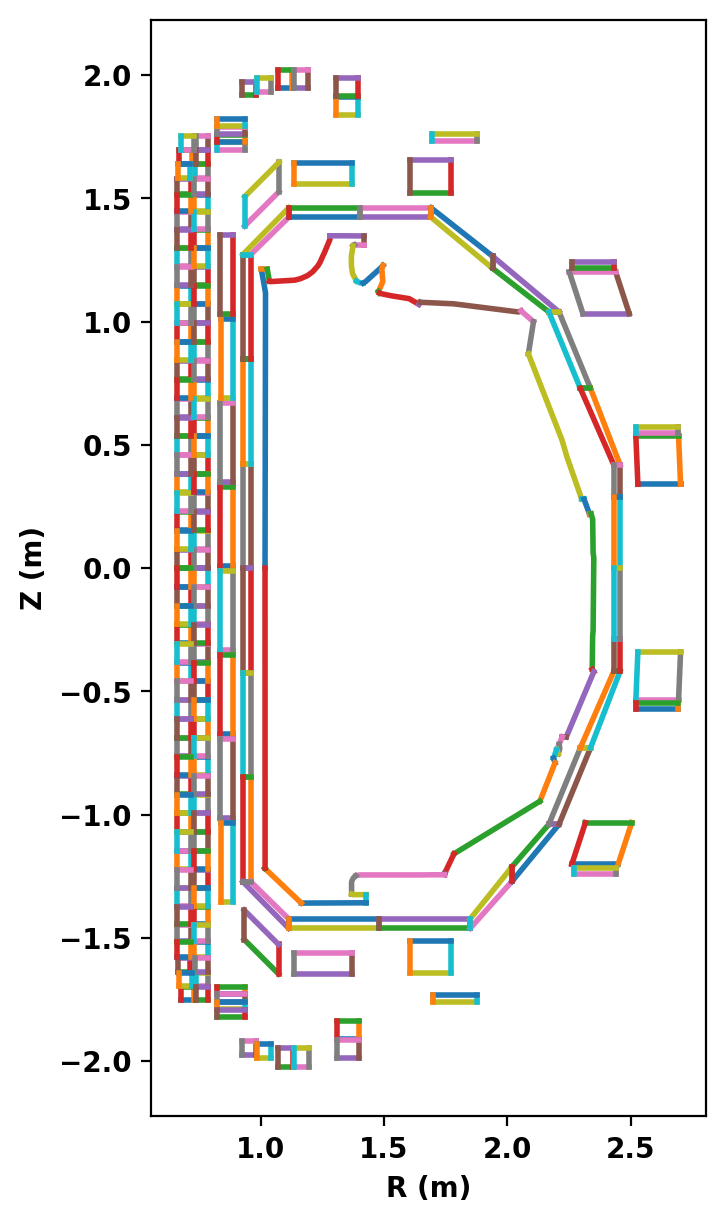

In [7]:
fig, ax = plt.subplots(1,1,figsize=(4,6),constrained_layout=True)
gs_mesh.plot_topology(fig,ax)

## Create mesh
Now we generate the actual mesh using the \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain.build_mesh "build_mesh()" method. Additionally, if `coil` and/or `conductor` regions are defined the \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain.get_coils "get_coils()" and \ref OpenFUSIONToolkit.TokaMaker.meshing.gs_Domain.get_conductors "get_conductors()" methods should also be called to get descriptive dictionaries for later use in TokaMaker. This step may take a few moments as [triangle](https://www.cs.cmu.edu/~quake/triangle.html) generates the mesh.

Note that, as is common with unstructured meshes, the mesh is stored a list of points `mesh_pts` of size (np,2), a list of cells formed from three points each `mesh_lc` of size (nc,3), and an array providing a region id number for each cell `mesh_reg` of size (nc,), which is mapped to the names above using the `coil_dict` and `cond_dict` dictionaries.

In [8]:
mesh_pts, mesh_lc, mesh_reg = gs_mesh.build_mesh()
coil_dict = gs_mesh.get_coils()
cond_dict = gs_mesh.get_conductors()

Assembling regions:


  # of unique points    = 3800
  # of unique segments  = 680


Generating mesh with Triangle:
  # of points  = 27961
  # of cells   = 55810
  # of regions = 167


## Plot resulting regions and grid
We now plot the mesh by region to inspect proper generation.

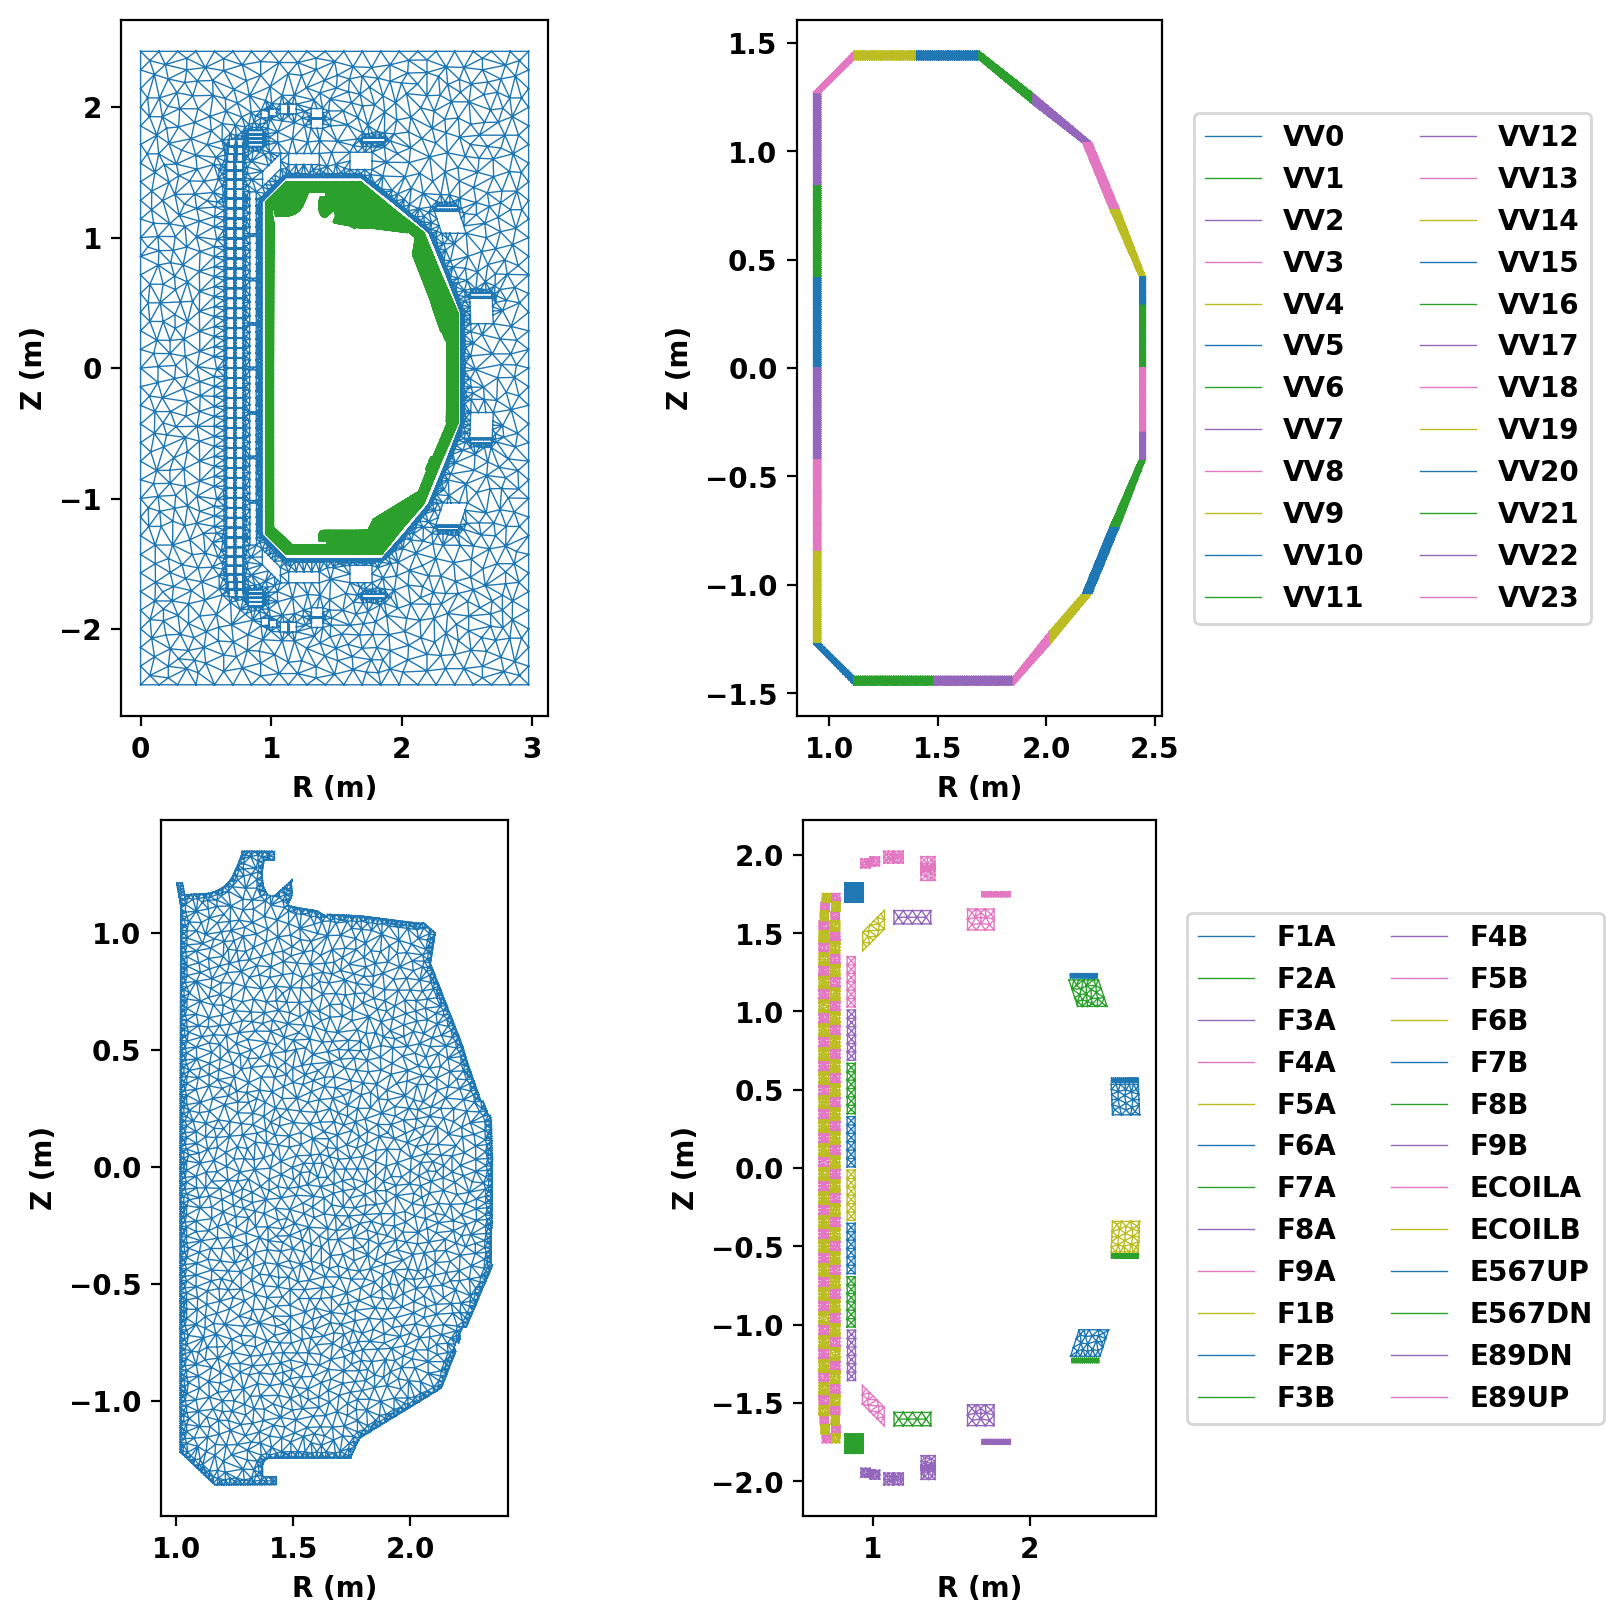

In [9]:
fig, ax = plt.subplots(2,2,figsize=(8,8),constrained_layout=True)
gs_mesh.plot_mesh(fig,ax)

### Zoom on the E-coil sets
The upper E-coil sets `E567UP` and `E89UP` are made of small one-turn blocks spread over the upper half of the device. We zoom in on them to check that every block is resolved.

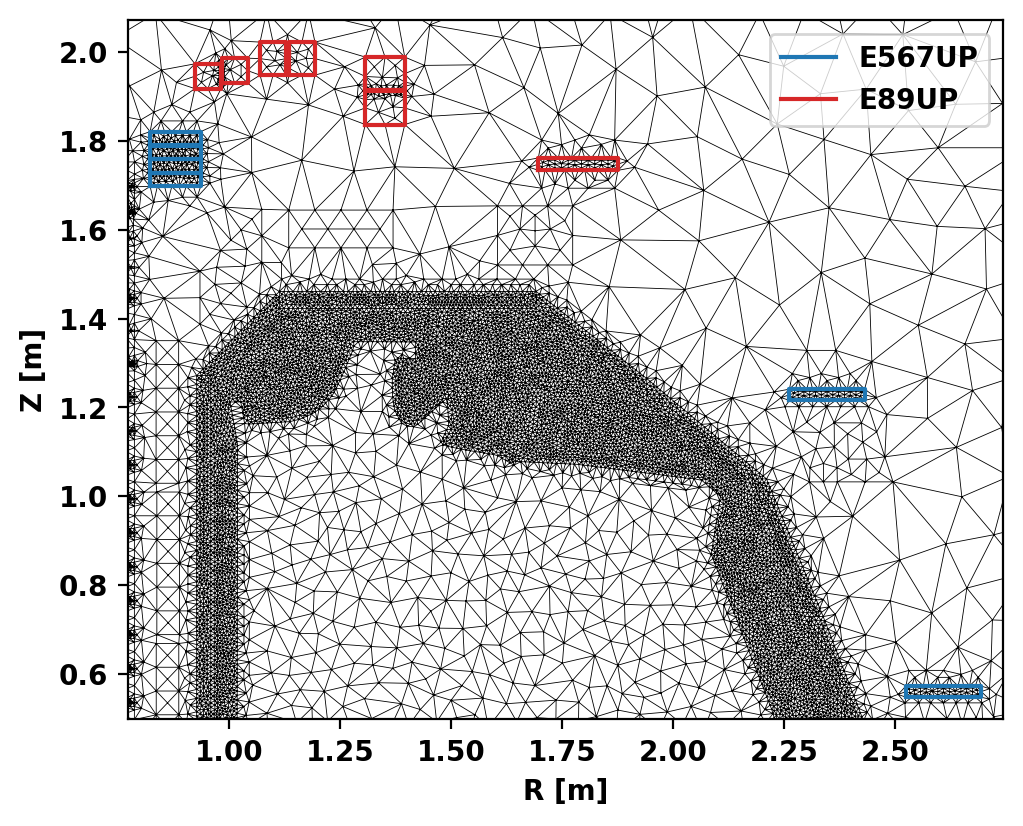

In [10]:
fig, ax = plt.subplots(1,1,figsize=(5,5),constrained_layout=True)
ax.triplot(mesh_pts[:,0],mesh_pts[:,1],mesh_lc,lw=0.3,color='k')
for key, color in (('E567UP','tab:blue'),('E89UP','tab:red')):
    for i, block in enumerate(DIIID_geom['coils'][key]['blocks']):
        pts = np.array(block['pts']+[block['pts'][0]])  # close the outline
        ax.plot(pts[:,0],pts[:,1],lw=1.5,color=color,label=key if i == 0 else None)
zoom_pts = np.vstack([block['pts'] for key in ('E567UP','E89UP') for block in DIIID_geom['coils'][key]['blocks']])
ax.set_xlim(zoom_pts[:,0].min()-0.05,zoom_pts[:,0].max()+0.05)
ax.set_ylim(zoom_pts[:,1].min()-0.05,zoom_pts[:,1].max()+0.05)
ax.set_aspect('equal')
ax.set_xlabel('R [m]')
ax.set_ylabel('Z [m]')
_ = ax.legend()

## Save mesh for later use
As generation of the mesh often takes comparable, or longer, time compare to runs in TokaMaker it is useful to separate generation of the mesh into a different script as demonstrated here. The method \ref OpenFUSIONToolkit.TokaMaker.meshing.save_gs_mesh "save_gs_mesh()" can be used to save the resulting information for later use. This is done using and an [HDF5](https://www.hdfgroup.org/solutions/hdf5/) file through the [h5py](https://www.h5py.org/) library.

In [11]:
save_gs_mesh(mesh_pts,mesh_lc,mesh_reg,coil_dict,cond_dict,'DIIID_mesh_v2.h5')